# Tutorial on Manifold Projection

This Colab is a self-contained playground for learning a projection map from samples. It has four parts:

1. **Projection model**
2. **Torus and circle union**
3. **k-torus in D-dim space ($D \ge 2k$)**
4. **MNIST experiment**

Run the cells from top to bottom.


In [ ]:
#@title Setup
%pip install -q torch torchvision matplotlib tqdm

import copy
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.func import jvp, vmap
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.utils import make_grid
from tqdm.auto import trange

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Device:", device)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

Device: cuda


## Part 1: Projection model

Let $X_1,\ldots,X_n\in\mathbb R^D$ be samples from an unknown manifold $M$. We learn a neural map $T:\mathbb R^D\to\mathbb R^D$ from perturbed points
$$
Y_{i,\ell}=X_i+\varepsilon_\ell,\qquad \varepsilon_\ell\sim\operatorname{Unif}(B_D(0,\delta)), \; i\in \{1,\cdots,n\} ,\; \ell\in \{1,\cdots, n_{noise}\}.
$$
For notation of simplicity, we use a single index $Y_j$, where $j=1,\cdots, N$ and $N=n * n_{noise}$.
Write $\pi_n(Y_j)$ for the nearest training sample and choose an inner radius $r_{\mathrm{inner}}<\delta$. The empirical objective used in the supplement is
$$
 E(T)=C_1  E_1+C_2  E_2+C_3 E_3,
$$
where
$$
 E_1=\frac1n\sum_{i=1}^n \|T(X_i)-X_i\|^2,
$$
$$
  E_2=\frac1m\sum_{j=1}^N
\left\|DT(T(Y_j))(T(Y_j)-Y_j)\right\|^2,
$$
$$
 E_3=\frac1m\sum_{j=1}^N
\left(\|T(Y_j)-\pi_n(Y_j)\|-r_{\mathrm{inner}}\right)_+.
$$

The terms respectively keep data fixed, suppress residual motion after projection, and keep outputs near the data manifold.

Training has two phases:

1. **Pretrain:** use $C_1=C_3=1,\ C_2=0$, with inner radius $r_{\mathrm{inner}}=0$.
2. **Projection train:** continue from the same weights with $C_1=C_2=C_3=1$ and the chosen $r_{\mathrm{inner}}$.

For difficult high-dimensional data, the iterated projection algorithm repeats these two phases at decreasing radii. At later stages it augments current-radius perturbations with points refined by the preceding stage.


In [ ]:
#@title Projection networks
class ProjectionNet(nn.Module):
    """MLP used by the vector experiments."""
    def __init__(self, ambient_dim, hidden=100, mid=200):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(ambient_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, mid), nn.SiLU(),
            nn.Linear(mid, hidden), nn.SiLU(),
            nn.Linear(hidden, ambient_dim),
        )

    def forward(self, x):
        return self.net(x)


class ProjectionUNet(nn.Module):
    """Time-independent U-Net used by the MNIST experiment."""
    def __init__(self, image_size=28, channels=(16, 32, 64, 128), in_channels=1):
        super().__init__()
        self.image_size = image_size
        self.in_channels = in_channels
        self.channels = list(channels)
        n = len(self.channels)

        def groups(ch, target=32):
            g = min(target, ch)
            while ch % g:
                g -= 1
            return g

        self.enc_convs, self.enc_norms = nn.ModuleList(), nn.ModuleList()
        sizes, cur = [], image_size
        for i, ch in enumerate(self.channels):
            stride = 1 if i == 0 else 2
            cur = (cur - 3) // stride + 1
            sizes.append(cur)
            in_ch = in_channels if i == 0 else self.channels[i - 1]
            self.enc_convs.append(nn.Conv2d(in_ch, ch, 3, stride=stride, bias=False))
            self.enc_norms.append(nn.GroupNorm(groups(ch, 4 if i == 0 else 32), ch))

        self.dec_tconvs, self.dec_norms = nn.ModuleList(), nn.ModuleList()
        for k in range(n - 1):
            in_ch = self.channels[-1] if k == 0 else 2 * self.channels[-1 - k]
            out_ch = self.channels[-2 - k]
            output_padding = sizes[-2 - k] - ((sizes[-1 - k] - 1) * 2 + 3)
            self.dec_tconvs.append(nn.ConvTranspose2d(
                in_ch, out_ch, 3, stride=2, output_padding=output_padding, bias=False
            ))
            self.dec_norms.append(nn.GroupNorm(groups(out_ch), out_ch))
        self.dec_final = nn.ConvTranspose2d(2 * self.channels[0], in_channels, 3)
        self.act = nn.SiLU()

    def forward(self, x):
        n_batch = x.shape[0] if x.dim() >= 2 else 1
        h = x.reshape(n_batch, self.in_channels, self.image_size, self.image_size)
        skips = []
        for conv, norm in zip(self.enc_convs, self.enc_norms):
            h = self.act(norm(conv(h)))
            skips.append(h)
        h = skips[-1]
        for k, (conv, norm) in enumerate(zip(self.dec_tconvs, self.dec_norms)):
            if k:
                h = torch.cat([h, skips[-1 - k]], dim=1)
            h = self.act(norm(conv(h)))
        return self.dec_final(torch.cat([h, skips[0]], dim=1)).reshape(n_batch, -1)


### Geometry Implemented Below

The next code cell defines the example manifold samplers used later in the tutorial, together with a shared perturbation sampler.

`sample_delta_ball(n, delta, ambient_dim)` samples uniformly from the $D$-dimensional ball of radius $\delta$. It draws a random Gaussian direction, normalizes it to the unit sphere, and multiplies by $\delta U^{1/D}$, where $U\sim\mathrm{Unif}(0,1)$; this radial scaling gives a volume-uniform point in the ball. `inject_randomness` applies this perturbation around every clean training anchor.


In [ ]:
#@title Manifolds and perturbations
def sample_delta_ball(n, delta, ambient_dim, device=device):
    z = torch.randn(ambient_dim, n, device=device)
    directions = z / z.norm(dim=0, keepdim=True).clamp_min(1e-12)
    radii = torch.rand(1, n, device=device).pow(1.0 / ambient_dim)
    return (delta * directions * radii).T


def inject_randomness(samples, delta, n_noise):
    flat_dim = int(np.prod(samples.shape[1:]))
    noise = sample_delta_ball(len(samples) * n_noise, delta, flat_dim, samples.device)
    noise = noise.reshape(len(samples), n_noise, *samples.shape[1:])
    return (samples[:, None] + noise).flatten(0, 1)


def nearest_samples(points, samples, block=2048):
    chunks = []
    for query in points.split(block):
        chunks.append(samples[torch.cdist(query, samples).argmin(dim=1)])
    return torch.cat(chunks)


def torus_and_circle_3d(n_torus=600, n_circle=100, R1=1.0, R2=0.4, Rc=1.0,
                        return_parts=False):
    if n_torus:
        u = 2 * torch.pi * torch.rand(n_torus)
        accepted = []
        while sum(len(x) for x in accepted) < n_torus:
            v = 2 * torch.pi * torch.rand(max(2 * n_torus, 1))
            keep = torch.rand_like(v) < (R1 + R2 * torch.cos(v)) / (R1 + R2)
            accepted.append(v[keep])
        v = torch.cat(accepted)[:n_torus]
        torus = torch.stack([
            (R1 + R2 * torch.cos(v)) * torch.cos(u),
            (R1 + R2 * torch.cos(v)) * torch.sin(u),
            R2 * torch.sin(v),
        ], dim=1)
    else:
        torus = torch.empty(0, 3)

    if n_circle:
        t = 2 * torch.pi * torch.rand(n_circle)
        circle = torch.stack([
            Rc + Rc * torch.cos(t), torch.zeros_like(t), Rc * torch.sin(t)
        ], dim=1)
    else:
        circle = torch.empty(0, 3)

    if return_parts:
        return torus, circle
    return torch.cat([torus, circle])


def torus_embedded(n=480, torus_dim=2, ambient_dim=256, density=None):
    if ambient_dim < 2 * torus_dim:
        raise ValueError("ambient_dim must be at least 2 * torus_dim")
    if density is None:
        density = [0.0] + [0.5] * max(torus_dim - 1, 0)
    if len(density) != torus_dim:
        raise ValueError("density must have one entry per torus angle")

    angles = []
    for a in density:
        accepted = []
        while sum(len(x) for x in accepted) < n:
            x = 2 * torch.pi * torch.rand(2 * n)
            keep = torch.rand_like(x) < (1 + a * torch.cos(x)) / (1 + a)
            accepted.append(x[keep])
        angles.append(torch.cat(accepted)[:n])
    alpha = torch.stack(angles, dim=1)
    points = torch.zeros(n, ambient_dim)
    for k in range(torus_dim):
        points[:, 2 * k] = torch.cos(alpha[:, k])
        points[:, 2 * k + 1] = torch.sin(alpha[:, k])
    return points


### Loss Implemented Below

For clean samples $X_i$, perturbed points $Y_j$, outputs $T(Y_j)$, and nearest training anchor $\pi_n(Y_j)$, the code evaluates the following loss
$$
E(T)=
C_1\frac1n\sum_i\|T(X_i)-X_i\|^2
+C_2\frac1m\sum_j\|DT(T(Y_j))[T(Y_j)-Y_j]\|^2
+C_3\frac1m\sum_j(\|T(Y_j)-\pi_n(Y_j)\|-r_{\mathrm{inner}})_+.
$$

The first term fixes the data, the second encourages idempotence in the correction direction, and the third keeps outputs near the training samples. We use the jvp operation to compute the Jacobian-vector product without forming a full $D\times D$ Jacobian, while vmap applies it across the batch. During mini-batch training, nearest-anchor search still uses the full training set. The training phase resamples perturbations every epoch, performs Adam updates, and optionally applies cosine learning-rate decay.


In [ ]:
#@title Loss and one training phase
def projection_loss(model, samples, noisy, output, weights, r_inner, reference=None):
    zero = output.new_tensor(0.0)
    fixed = ((model(samples) - samples).norm(dim=1) ** 2).mean()

    jacobian = zero
    if weights.get("C2", 0):
        vectors = output - noisy
        def one_jvp(x, v):
            return jvp(model, (x,), (v,))[1]
        jv = vmap(one_jvp)(output, vectors)
        jacobian = (jv.norm(dim=1) ** 2).mean()

    locality = zero
    if weights.get("C3", 0):
        closest = nearest_samples(noisy, samples if reference is None else reference)
        locality = torch.relu((output - closest).norm(dim=1) - r_inner).mean()

    return (
        weights.get("C1", 0) * fixed
        + weights.get("C2", 0) * jacobian
        + weights.get("C3", 0) * locality
    )


def train_phase(model, samples, *, delta, epochs, lr, n_noise, weights,
                r_inner, batch_size=None, scheduler="constant",
                previous_model=None, previous_delta=None, previous_n_noise=0,
                description="training", position=0, leave_progress=True):
    samples = samples.cpu()
    reference = samples.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    schedule = (
        torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs)
        if scheduler == "cosine" else None
    )
    iterator = trange(
        epochs, desc=description, position=position,
        leave=leave_progress, dynamic_ncols=True
    )
    for _ in iterator:
        loader = (
            DataLoader(samples, batch_size=batch_size, shuffle=True)
            if batch_size else [samples]
        )
        last = None
        for batch in loader:
            batch = batch.to(device)
            noisy = inject_randomness(batch, delta, n_noise)
            if previous_model is not None:
                previous_model.eval()
                with torch.no_grad():
                    refined = previous_model(
                        inject_randomness(batch, previous_delta, previous_n_noise)
                    )
                noisy = torch.cat([noisy, refined], dim=0)

            optimizer.zero_grad(set_to_none=True)
            output = model(noisy)
            last = projection_loss(
                model, batch, noisy, output, weights, r_inner, reference
            )
            last.backward()
            optimizer.step()
        if schedule:
            schedule.step()
        iterator.set_postfix(loss=f"{last.item():.4f}")
    return model


### Algorithms Implemented Below

**Algorithm 1: two-stage projection training**

1. Initialize $T_\theta$. Pretrain for **pretrain_steps** updates with $C_1=C_3=1$, $C_2=0$, and inner radius zero.
2. Continue from those weights for **projection_steps** updates with $C_1=C_2=C_3=1$ and inner radius **r_inner**.
3. Return the trained projection map for this radius.

**Algorithm 2: iterated projection algorithm**

Choose decreasing radii $\delta_1>\delta_2>\cdots>\delta_K$. At stage $k$, train a projection map $T_k$ at radius $\delta_k$, warm-starting from the previous stage. For $k>1$, the training batch includes current-radius perturbations together with points produced by applying the frozen previous map $T_{k-1}$ to larger-radius perturbations.

The final projection map is the composition

$$
T_{\mathrm{IPA}}=T_K\circ T_{K-1}\circ\cdots\circ T_1.
$$

To generate new samples, start from the largest noisy neighborhood $Y=X+\varepsilon$ with $\varepsilon\sim\mathrm{Unif}(B_D(0,\delta_1))$, then apply the composition:

$$
\widehat X=T_{\mathrm{IPA}}(Y)=T_K(T_{K-1}(\cdots T_1(Y)\cdots)).
$$

In code, `mnist_snapshots` stores the maps in composition order, so generation loops through the snapshots once from first to last.


In [ ]:
#@title Algorithms 1 and 2
PRETRAIN_WEIGHTS = {"C1": 1.0, "C3": 1.0}
PROJECTION_WEIGHTS = {"C1": 1.0, "C2": 1.0, "C3": 1.0}

def train_algorithm1(model, samples, *, delta, r_inner, pretrain_steps, projection_steps,
                     lr_pretrain, lr_projection, n_noise, batch_size=None,
                     scheduler_projection="cosine", previous_model=None,
                     previous_delta=None, previous_n_noise=0,
                     progress_prefix="", progress_start=0):
    label = f"{progress_prefix} " if progress_prefix else ""
    train_phase(
        model, samples, delta=delta, epochs=pretrain_steps, lr=lr_pretrain,
        n_noise=n_noise, weights=PRETRAIN_WEIGHTS, r_inner=0.0,
        batch_size=batch_size, scheduler="constant",
        previous_model=previous_model, previous_delta=previous_delta,
        previous_n_noise=previous_n_noise,
        description=f"{label}pretrain", position=progress_start,
        leave_progress=True,
    )
    pretrain_snapshot = copy.deepcopy(model).eval()
    train_phase(
        model, samples, delta=delta, epochs=projection_steps, lr=lr_projection,
        n_noise=n_noise, weights=PROJECTION_WEIGHTS, r_inner=r_inner,
        batch_size=batch_size, scheduler=scheduler_projection,
        previous_model=previous_model, previous_delta=previous_delta,
        previous_n_noise=previous_n_noise,
        description=f"{label}projection", position=progress_start + 1,
        leave_progress=True,
    )
    return pretrain_snapshot, copy.deepcopy(model).eval()


def train_algorithm2(model, samples, *, deltas, r_inners, pretrain_steps,
                     projection_steps, lr_pretrain, lr_projection,
                     previous_n_noise, batch_size):
    snapshots, previous = [], None
    total = len(deltas)
    for k, (delta, r_inner) in enumerate(zip(deltas, r_inners)):
        current_n_noise = previous_n_noise if k == 0 else 2
        pre, full = train_algorithm1(
            model, samples, delta=delta, r_inner=r_inner,
            pretrain_steps=pretrain_steps[k], projection_steps=projection_steps[k],
            lr_pretrain=lr_pretrain, lr_projection=lr_projection,
            n_noise=current_n_noise, batch_size=batch_size,
            scheduler_projection="constant",
            previous_model=previous,
            previous_delta=deltas[k - 1] if k else None,
            previous_n_noise=previous_n_noise if k else 0,
            progress_prefix=f"stage {k + 1}/{total}",
            progress_start=2 * k,
        )
        snapshots.extend([pre, full])
        previous = full
    return snapshots


@torch.no_grad()
def apply_repeatedly(model, points, applications):
    model.eval()
    for _ in range(applications):
        points = model(points)
    return points


### Choosing hyperparameters

- Standardize the data scale before choosing radii. Pick $\delta$ large enough to cover the region from which samples will be generated, and choose $0<r_{\mathrm{inner}}<\delta$, typically we choose $r_{\mathrm{inner}} = \delta/2$.
- Pretraining usually tolerates a larger learning rate. Continue with a smaller learning rate for the Jacobian-regularized phase.
- Use more perturbations per anchor when the training set is small. Mini-batches are useful for image datasets.
- Reapply a trained map a small number of times for better generation. For high-dimensional data, decreasing-radius stages are often more reliable than one very large jump.


## Part 2: Torus and Circle Union

This example learns a projection map for a disconnected manifold $M=M_{\mathrm{torus}}\cup M_{\mathrm{circle}}\subset\mathbb R^3$. The torus component is

$$
x_{\mathrm{torus}}(u,v)=((R_1+R_2\cos v)\cos u,\ (R_1+R_2\cos v)\sin u,\ R_2\sin v),
$$

with $u,v\in[0,2\pi)$, and the circle component is

$$
x_{\mathrm{circle}}(t)=(R_c+R_c\cos t,\ 0,\ R_c\sin t),
$$

with $t\in[0,2\pi)$. The model sees only sampled points from this union, not the analytic parameters, and use **Algorithm 1**.

**Controls in the training cell**

- **seed:** random seed for the training data and optimization.
- **n_torus**, **n_circle:** clean training anchors on the torus surface and circle curve.
- **delta:** radius of the outer perturbation balls used for training.
- **r_inner:** tolerated output distance from the nearest training anchor in the locality term; keep it below **delta**.
- **pretrain_steps**, **projection_steps:** update counts for the two Algorithm 1 phases.
- **lr_pretrain**, **lr_projection:** Adam learning rates for the two phases.
- **n_noise:** number of noisy points per training sample.

**Controls in the generation cell**
- **applications:** how many times to reapply the trained projection map to the noisy starting points.
- **n_generated:** total number of noisy starting points to draw and project, it's also the number of generated new samples.



In [ ]:
#@title Train the torus-and-circle map
seed = 2 #@param {type:"integer"}
n_torus = 600 #@param {type:"integer"}
n_circle = 200 #@param {type:"integer"}
delta = 0.25 #@param {type:"number"}
r_inner = 0.125 #@param {type:"number"}
pretrain_steps = 3000 #@param {type:"integer"}
projection_steps = 2000 #@param {type:"integer"}
lr_pretrain = 0.006 #@param {type:"number"}
lr_projection = 0.001 #@param {type:"number"}
n_noise = 10 #@param {type:"integer"}

union_config = dict(
    seed=seed, n_torus=n_torus, n_circle=n_circle,
    delta=delta, r_inner=r_inner,
    pretrain_steps=pretrain_steps, projection_steps=projection_steps,
    lr_pretrain=lr_pretrain, lr_projection=lr_projection,
    n_noise=n_noise,
)
set_seed(union_config["seed"])

if union_config["n_torus"] <= 0 or union_config["n_circle"] <= 0:
    raise ValueError("Require positive n_torus and n_circle")
if not 0 <= union_config["r_inner"] < union_config["delta"]:
    raise ValueError("Require 0 <= r_inner < delta")

union_torus_samples, union_circle_samples = torus_and_circle_3d(
    n_torus=union_config["n_torus"],
    n_circle=union_config["n_circle"],
    return_parts=True,
)
union_samples = torch.cat([union_torus_samples, union_circle_samples], dim=0)
union_model = ProjectionNet(3).to(device)
_ = train_algorithm1(
    union_model, union_samples,
    delta=union_config["delta"], r_inner=union_config["r_inner"],
    pretrain_steps=union_config["pretrain_steps"],
    projection_steps=union_config["projection_steps"],
    lr_pretrain=union_config["lr_pretrain"],
    lr_projection=union_config["lr_projection"],
    n_noise=union_config["n_noise"], scheduler_projection="cosine",
)


pretrain:   0%|          | 0/3000 [00:00<?, ?it/s]

projection:   0%|          | 0/2000 [00:00<?, ?it/s]

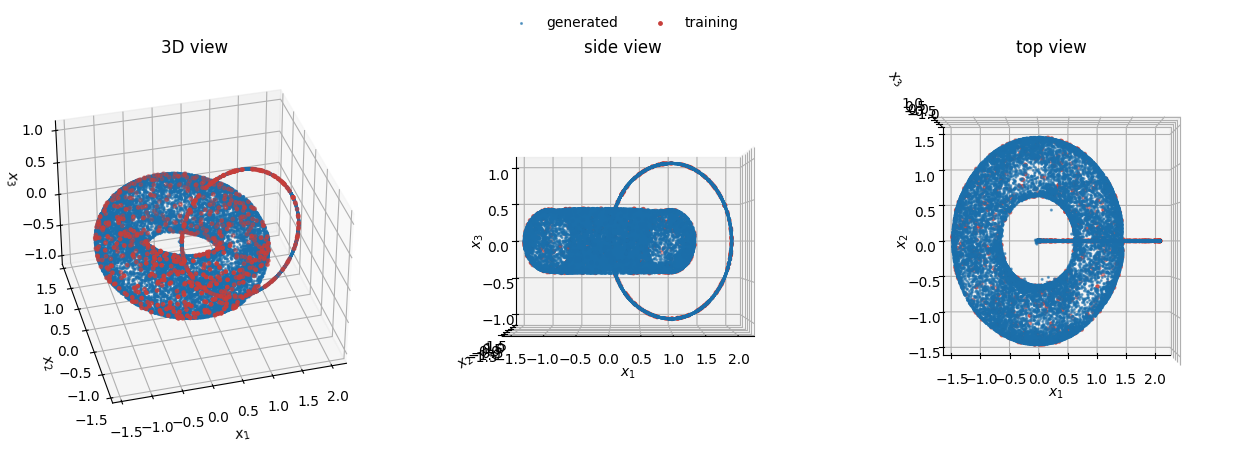

In [ ]:
#@title Generate and view samples
applications = 2 #@param {type:"integer"}
n_generated = 20000 #@param {type:"integer"}

if applications <= 0:
    raise ValueError("applications must be positive")
if n_generated <= 0:
    raise ValueError("n_generated must be positive")

set_seed(union_config["seed"] + 100)
idx = torch.randint(len(union_samples), (n_generated,))
union_start = inject_randomness(
    union_samples[idx].to(device), union_config["delta"], 1
)
union_generated = apply_repeatedly(union_model, union_start, applications).cpu()

fig = plt.figure(figsize=(13, 4.3))
legend_handles = None
for i, (elev, azim, title) in enumerate([
    (35, -105, "3D view"), (0, -90, "side view"), (90, -90, "top view")
], 1):
    ax = fig.add_subplot(1, 3, i, projection="3d")
    gen = ax.scatter(
        *union_generated.T, s=1.5, alpha=0.55, color="#1b6fab",
        label="generated"
    )
    train = ax.scatter(
        *union_samples.T, s=6, color="#c73e3a", label="training"
    )
    if legend_handles is None:
        legend_handles = [gen, train]
    ax.view_init(elev, azim)
    ax.set_title(title)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_3$")
fig.legend(
    legend_handles, ["generated", "training"],
    loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.03)
)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()


## Part 3: $k$-Torus in $D$-dim Space

This example embeds a $k$-torus in the first $2k$ coordinates of $\mathbb R^D$:

$$
x(\alpha_1,\ldots,\alpha_k)=(\cos\alpha_1,\sin\alpha_1,\ldots,\cos\alpha_k,\sin\alpha_k,0,\ldots,0).
$$

The default setting is $k=2$ and $D=256$, using **Algorithm 1**. A radius-7 perturbation ball is large in that ambient space, so the example tests whether one projection map can remove many irrelevant-coordinate perturbations while preserving the angular coordinates.

In general, we suggest choosing $\delta ≈ \sqrt{D/(2k)}$.

**Controls in the training cell** have the same generic names as Part 2.

 **intrinsic_dim** is $k$, **ambient_dim** is $D$, **n** is the number of clean training anchors, and **n_noise** is the number of noisy points per anchor during training. The plot cell controls generation separately.


In [ ]:
#@title Train the torus projection map
seed = 2 #@param {type:"integer"}
n = 480 #@param {type:"integer"}
intrinsic_dim = 2 #@param {type:"integer"}
ambient_dim = 256 #@param {type:"integer"}
delta = 7.0 #@param {type:"number"}
r_inner = 1.75 #@param {type:"number"}
pretrain_steps = 400 #@param {type:"integer"}
projection_steps = 2000 #@param {type:"integer"}
lr_pretrain = 0.005 #@param {type:"number"}
lr_projection = 0.001 #@param {type:"number"}
n_noise = 50 #@param {type:"integer"}

if n <= 0:
    raise ValueError("n must be positive")
if intrinsic_dim < 1:
    raise ValueError("intrinsic_dim must be positive")
if ambient_dim < max(3, 2 * intrinsic_dim):
    raise ValueError("ambient_dim must be at least max(3, 2 * intrinsic_dim)")

torus_config = dict(
    seed=seed, n=n, intrinsic_dim=intrinsic_dim, ambient_dim=ambient_dim,
    delta=delta, r_inner=r_inner,
    pretrain_steps=pretrain_steps, projection_steps=projection_steps,
    lr_pretrain=lr_pretrain, lr_projection=lr_projection,
    n_noise=n_noise,
)
set_seed(torus_config["seed"])

if not 0 <= torus_config["r_inner"] < torus_config["delta"]:
    raise ValueError("Require 0 <= r_inner < delta")

torus_density = [0.0] + [0.5] * (torus_config["intrinsic_dim"] - 1)
torus_samples = torus_embedded(
    n=torus_config["n"], torus_dim=torus_config["intrinsic_dim"],
    ambient_dim=torus_config["ambient_dim"], density=torus_density,
)
torus_model = ProjectionNet(torus_config["ambient_dim"]).to(device)
_ = train_algorithm1(
    torus_model, torus_samples,
    delta=torus_config["delta"], r_inner=torus_config["r_inner"],
    pretrain_steps=torus_config["pretrain_steps"],
    projection_steps=torus_config["projection_steps"],
    lr_pretrain=torus_config["lr_pretrain"],
    lr_projection=torus_config["lr_projection"],
    n_noise=torus_config["n_noise"], scheduler_projection="cosine",
)


pretrain:   0%|          | 0/400 [00:00<?, ?it/s]

projection:   0%|          | 0/2000 [00:00<?, ?it/s]

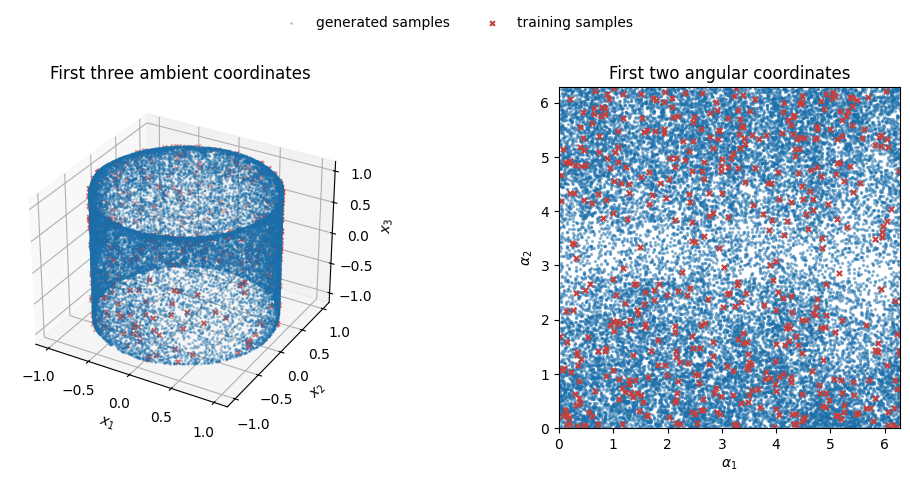

In [ ]:
#@title Generate and view the learned torus
applications = 2 #@param {type:"integer"}
n_generated = 24000 #@param {type:"integer"}

if n_generated <= 0:
    raise ValueError("n_generated must be positive")
set_seed(torus_config["seed"] + 100)
idx = torch.randint(len(torus_samples), (n_generated,))
torus_start = inject_randomness(
    torus_samples[idx].to(device), torus_config["delta"], 1
)
torus_generated = apply_repeatedly(torus_model, torus_start, applications).cpu()

generated_angle_1 = torch.atan2(
    torus_generated[:, 1], torus_generated[:, 0]
) % (2 * torch.pi)
training_angle_1 = torch.atan2(
    torus_samples[:, 1], torus_samples[:, 0]
) % (2 * torch.pi)

fig = plt.figure(figsize=(11, 4.7))
ax = fig.add_subplot(1, 2, 1, projection="3d")
gen = ax.scatter(
    torus_generated[:, 0], torus_generated[:, 1], torus_generated[:, 2],
    s=1, alpha=0.3, color="#1b6fab", label="generated samples"
)
train = ax.scatter(
    torus_samples[:, 0], torus_samples[:, 1], torus_samples[:, 2],
    s=12, marker="x", color="#c73e3a", label="training samples"
)
ax.set_title("First three ambient coordinates")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_3$")

ax = fig.add_subplot(1, 2, 2)
if torus_config["intrinsic_dim"] >= 2:
    generated_angle_2 = torch.atan2(
        torus_generated[:, 3], torus_generated[:, 2]
    ) % (2 * torch.pi)
    training_angle_2 = torch.atan2(
        torus_samples[:, 3], torus_samples[:, 2]
    ) % (2 * torch.pi)
    ax.scatter(generated_angle_1, generated_angle_2, s=2, alpha=0.4, color="#1b6fab")
    ax.scatter(training_angle_1, training_angle_2, s=14, marker="x", color="#c73e3a")
    ax.set(xlim=(0, 2 * np.pi), ylim=(0, 2 * np.pi),
           xlabel=r"$\alpha_1$", ylabel=r"$\alpha_2$",
           title="First two angular coordinates")
    ax.set_aspect("equal")
else:
    ax.hist(generated_angle_1.numpy(), bins=60, alpha=0.4, color="#1b6fab", label="generated samples")
    ax.hist(training_angle_1.numpy(), bins=30, histtype="step", linewidth=1.5,
            color="#c73e3a", label="training samples")
    ax.set(xlim=(0, 2 * np.pi), xlabel=r"$\alpha_1$", title="Angular coordinate")
fig.legend(
    [gen, train], ["generated samples", "training samples"],
    loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.03)
)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()


## Part 4: MNIST Experiment

Images live in $\mathbb R^{784}$, so this example uses the **U-Net and Algorithm 2**. Each stage is warm-started; generation composes the trained projection snapshots in order.

You can either load the shared MNIST projection checkpoint and go directly to generated samples, or train the checkpoint yourself. Loading is the fastest path for trying the notebook. Training from scratch with the default settings takes around 1 hour on an A100 GPU.

**Controls in the next cell**

- **load_saved_checkpoint:** load the shared checkpoint instead of training from scratch.
- **checkpoint_path:** local path where the checkpoint is stored after it is fetched.
- **seed:** random seed for the MNIST training subset and optimization when training from scratch.
- **n:** number of training images.
- **deltas**, **r_inners:** comma-separated stage radii. They must have equal length, outer radii must strictly decrease, and inner radii must not increase.
- **pretrain_steps**, **projection_steps:** updates per stage for the two phases.
- **lr_pretrain**, **lr_projection:** phase learning rates.
- **n_noise:** previous-radius refined anchors per clean image; stage 1 also uses this many current-radius perturbations.
- **batch_size:** clean-image mini-batch size. Lower it if GPU memory is limited.


In [ ]:
#@title Load or train MNIST projection map
load_saved_checkpoint = True #@param {type:"boolean"}
checkpoint_path = "mnist_projection_checkpoint.pt"
shared_checkpoint_url = "https://drive.google.com/uc?id=1doduENF-FwJtS-YByTXTqfBUuJAJqwMQ"
save_checkpoint_after_training = True #@param {type:"boolean"}
seed = 4 #@param {type:"integer"}
n = 10000 #@param {type:"integer"}
deltas = "20, 8, 4" #@param {type:"string"}
r_inners = "8, 4, 2" #@param {type:"string"}
pretrain_steps = 100 #@param {type:"integer"}
projection_steps = 50 #@param {type:"integer"}
lr_pretrain = 0.002 #@param {type:"number"}
lr_projection = 0.0005 #@param {type:"number"}
n_noise = 50 #@param {type:"integer"}
batch_size = 64 #@param {type:"integer"}

from pathlib import Path
import subprocess
import sys

if load_saved_checkpoint:
    checkpoint_file = Path(checkpoint_path)
    if not checkpoint_file.exists():
        try:
            import gdown
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
            import gdown
        print(f"Fetching checkpoint to {checkpoint_path}")
        gdown.download(shared_checkpoint_url, checkpoint_path, quiet=False)

    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    mnist_config = checkpoint["config"]
    mnist_config.setdefault("n_noise", n_noise)
    mnist_samples = checkpoint["samples"].float().contiguous()
    mnist_deltas = [float(x) for x in mnist_config["deltas"]]
    mnist_r_inners = [float(x) for x in mnist_config["r_inners"]]
    mnist_steps = (
        [int(x) for x in mnist_config["pretrain_steps"]],
        [int(x) for x in mnist_config["projection_steps"]],
    )
    mnist_snapshots = []
    for state in checkpoint["snapshot_state_dicts"]:
        snapshot = ProjectionUNet(
            image_size=28, channels=(16, 32, 64, 128), in_channels=1
        )
        snapshot.load_state_dict(state)
        mnist_snapshots.append(snapshot.eval())
    print(f"Loaded checkpoint: {checkpoint_path}")
    print("Training images:", len(mnist_samples))
else:
    mnist_config = dict(
        seed=seed, n=n, deltas=deltas, r_inners=r_inners,
        pretrain_steps=pretrain_steps, projection_steps=projection_steps,
        lr_pretrain=lr_pretrain, lr_projection=lr_projection,
        n_noise=n_noise, batch_size=batch_size,
    )
    set_seed(mnist_config["seed"])

    dataset = MNIST(root="./data", train=True, download=True)
    all_images = dataset.data.float().div(255).reshape(-1, 784)
    permutation = torch.randperm(len(all_images))
    mnist_samples = all_images[permutation[:mnist_config["n"]]].contiguous()

    mnist_deltas = [float(x) for x in mnist_config["deltas"].split(",")]
    mnist_r_inners = [float(x) for x in mnist_config["r_inners"].split(",")]
    if len(mnist_deltas) != len(mnist_r_inners):
        raise ValueError("deltas and inner radii must have equal length")
    if any(b >= a for a, b in zip(mnist_deltas, mnist_deltas[1:])):
        raise ValueError("deltas must be strictly decreasing")
    if any(b > a for a, b in zip(mnist_r_inners, mnist_r_inners[1:])):
        raise ValueError("inner radii must be non-increasing")

    mnist_steps = (
        [mnist_config["pretrain_steps"]] * len(mnist_deltas),
        [mnist_config["projection_steps"]] * len(mnist_deltas),
    )
    mnist_config["deltas"] = mnist_deltas
    mnist_config["r_inners"] = mnist_r_inners
    mnist_config["pretrain_steps"] = mnist_steps[0]
    mnist_config["projection_steps"] = mnist_steps[1]
    print("Training images:", len(mnist_samples))

    mnist_model = ProjectionUNet(
        image_size=28, channels=(16, 32, 64, 128), in_channels=1
    ).to(device)

    mnist_snapshots = train_algorithm2(
        mnist_model, mnist_samples,
        deltas=mnist_deltas,
        r_inners=mnist_r_inners,
        pretrain_steps=mnist_steps[0],
        projection_steps=mnist_steps[1],
        lr_pretrain=mnist_config["lr_pretrain"],
        lr_projection=mnist_config["lr_projection"],
        previous_n_noise=mnist_config["n_noise"],
        batch_size=mnist_config["batch_size"],
    )

    if save_checkpoint_after_training:
        checkpoint = {
            "config": mnist_config,
            "samples": mnist_samples.cpu(),
            "snapshot_state_dicts": [
                snapshot.cpu().state_dict() for snapshot in mnist_snapshots
            ],
        }
        torch.save(checkpoint, checkpoint_path)
        print(f"Saved checkpoint: {checkpoint_path}")


In [ ]:
#@title Generate and display MNIST samples
display_count = 64 #@param {type:"slider", min:16, max:128, step:16}
comparison_count = 8 #@param {type:"slider", min:4, max:16, step:4}
set_seed(mnist_config["seed"] + 100)
indices = torch.randperm(len(mnist_samples))[:display_count]
parent_samples = mnist_samples[indices].to(device)
mnist_start = inject_randomness(parent_samples, mnist_deltas[0], 1)

with torch.no_grad():
    mnist_generated = mnist_start
    for snapshot in mnist_snapshots:
        snapshot = snapshot.to(device).eval()
        mnist_generated = snapshot(mnist_generated)
    closest_training = nearest_samples(mnist_generated, mnist_samples.to(device))

nrow = min(8, display_count)
generated_grid = make_grid(
    mnist_generated.reshape(-1, 1, 28, 28).cpu().clamp(0, 1),
    nrow=nrow, padding=2, pad_value=1
)

comparison_count = min(comparison_count, display_count)
comparison_images = [
    mnist_generated[:comparison_count],
    mnist_start[:comparison_count],
    parent_samples[:comparison_count],
    closest_training[:comparison_count],
]
comparison_titles = ["Generated", "Noised", "Parent training", "Closest training"]
noised_l2 = (mnist_generated - mnist_start).norm(dim=1).detach().cpu()
parent_l2 = (mnist_generated - parent_samples).norm(dim=1).detach().cpu()
closest_l2 = (mnist_generated - closest_training).norm(dim=1).detach().cpu()

fig = plt.figure(figsize=(14, max(5, 1.75 * comparison_count)))
outer = fig.add_gridspec(1, 2, width_ratios=[1.05, 2.6], wspace=0.18)

left_ax = fig.add_subplot(outer[0, 0])
left_ax.imshow(generated_grid.permute(1, 2, 0), cmap="gray")
left_ax.set_title(f"Projection-map samples (n={display_count})")
left_ax.axis("off")

right_grid = outer[0, 1].subgridspec(comparison_count, 4, wspace=0.08, hspace=0.55)
for row in range(comparison_count):
    row_distances = [None, noised_l2[row], parent_l2[row], closest_l2[row]]
    for col in range(4):
        ax = fig.add_subplot(right_grid[row, col])
        image = comparison_images[col][row].reshape(28, 28).detach().cpu().clamp(0, 1)
        ax.imshow(image, cmap="gray", vmin=0, vmax=1)
        if row_distances[col] is None:
            title = comparison_titles[col]
        else:
            title = f"{comparison_titles[col]}\nL2={row_distances[col]:.3f}"
        ax.set_title(title, fontsize=8)
        ax.axis("off")

plt.show()


In [ ]:
#@title Free up memory
import gc, torch

gc.collect()
torch.cuda.empty_cache()

print("GPU cache cleared!")

GPU cache cleared!


The same workflow applies to a new dataset: choose a perturbation radius $\delta$ that covers the generation region, train the projection map to fix clean samples and remove off-manifold perturbations, then generate by starting from noisy anchors and applying the learned map.
